# 02 · Train OneK1K reference ensembles

[Previous: data and embeddings](01_data_and_embeddings.ipynb) · [Tutorial index](../README.md#try-it-out)

Let's start with **memory B cells**: one cell type, five independent MLPs.
Set `CELL_TYPE` in the first code cell to choose another expression label, and
use the same choice in notebooks 03 and 04. Each member predicts an expression
mean and variance from reference-genome blood embeddings. Notebook 03 applies
this teacher ensemble to Geuvadis personalized embeddings and distills its
predictions; no Geuvadis expression labels are needed.

Outputs stay together under `outputs/tutorial/onek1k/memory_B_cell/` by default.
Changing the cell type selects a separate output directory.

For a shortcut, download the [**ready-made OneK1K linear models from Hugging Face**](https://huggingface.co/Padraig7/atticus-onek1k) and unpack the complete model directory, including covariance files, to `models/onek1k/`. You can then skip training and distillation, head straight to [04 · Association testing](04_twas.ipynb), and choose the pretrained `models/onek1k` path.

In [1]:
CELL_TYPE = "memory B cell"  # Use the same label in notebooks 02–04.

from pathlib import Path
import sys

ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / "pyproject.toml").is_file()
             and (path / "src/training/run.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository or its notebooks/ directory.")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks"))
from tutorial import ROOT, paths_for_cell_type, run, uv, require, file_fingerprint, load_native_checkpoint

EXECUTE = True
WANDB_ARGS = ["--wandb-mode", "disabled"]

PATHS = paths_for_cell_type(CELL_TYPE)


## Check the two training inputs

Both inputs are available from the [OneK1K dataset on Hugging Face](https://huggingface.co/datasets/Padraig7/atticus-onek1k). After downloading, place them at the paths below:

| Input | What it should contain |
| --- | --- |
| `data/onek1k/expression.h5ad` | Mean raw counts in `X`; one row per individual/cell-type pair, `obs.individual_id`, `obs.cell_type`, and Ensembl gene IDs in `var_names`. See the [expression format](../docs/command_reference.md#expression-file). |
| `data/onek1k/embeddings/reference/REFERENCE.npz` | Reference-genome `features`, `ensids`, `chroms`, and the archive's model metadata. |

`PATHS` picks `data/onek1k/embeddings/reference/REFERENCE.npz` when available,
otherwise `data/embeddings/reference/REFERENCE.npz` from notebook 01.
Downloaded OneK1K reference embeddings work directly: no VariantFormer installation or inference is needed for this notebook.

The next cell reads observation and gene metadata without loading the expression
matrix. Later steps use the checkpoint written by `src/training/run.py`.


In [2]:
import anndata as ad
import numpy as np
import pandas as pd
from IPython.display import display
from src.training.dataset import CHROMOSOMES, gene_ids, split_individuals
from src.preprocessing.geuvadis import read_ids

HELD_OUT_INDIVIDUALS = ROOT / "data/data-for-the-paper/test-individuals/onek1k.txt"

reference = PATHS["reference"]
training_inputs = [PATHS["expression"], reference]
display(pd.DataFrame({"input": [str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path)
                               for path in training_inputs],
                      "exists": [path.is_file() for path in training_inputs]}))

if all(path.is_file() for path in training_inputs):
    with np.load(reference, allow_pickle=False) as archive:
        genes, chroms = gene_ids(archive["ensids"]), archive["chroms"]
    chroms = np.asarray([str(chrom).lower().removeprefix("chr").upper() for chrom in chroms])
    expression = ad.read_h5ad(PATHS["expression"], backed="r")
    try:
        required_columns = {"individual_id", "cell_type"}
        if not required_columns <= set(expression.obs.columns):
            raise ValueError("The downloaded expression file must include obs.individual_id and obs.cell_type.")
        if expression.obs[list(required_columns)].isna().any().any():
            raise ValueError("Individual and cell-type labels must not be missing.")
        if expression.obs.duplicated(["individual_id", "cell_type"]).any():
            raise ValueError("Expected one pseudo-bulk row per individual/cell-type pair.")
        training_ids, held_out_ids = split_individuals(
            expression.obs.individual_id.astype(str), seed=42,
            held_out=read_ids(HELD_OUT_INDIVIDUALS) if HELD_OUT_INDIVIDUALS else None,
        )
        available_cells = sorted(expression.obs.cell_type.unique())
        if CELL_TYPE not in available_cells:
            raise ValueError(f"Choose CELL_TYPE from: {available_cells}")
        selected_rows = int((expression.obs.cell_type == CELL_TYPE).sum())
        aligned = np.isin(genes, gene_ids(expression.var_names))
        print(f"Individuals: {len(training_ids)} training, {len(held_out_ids)} held out")
        print(f"Cell type: {CELL_TYPE}")
        print(f"Selected pseudo-bulk rows: {selected_rows:,}; expression genes: {expression.n_vars:,}")
        display(pd.DataFrame([
            {"partition": name, "chromosomes": ", ".join(chromosomes),
             "aligned_genes": int(np.count_nonzero(aligned & np.isin(chroms, chromosomes)))}
            for name, chromosomes in CHROMOSOMES.items()
        ]))
    finally:
        expression.file.close()
else:
    print("Place the downloaded expression file at data/onek1k/expression.h5ad; "
          "generate any missing reference embeddings in notebook 01.")


,input,exists
0,data/onek1k/expression.h5ad,True
1,data/onek1k/embeddings/reference/REFERENCE.npz,True


Individuals: 781 training, 200 held out
Cell type: memory B cell
Selected pseudo-bulk rows: 981; expression genes: 17,967


,partition,chromosomes,aligned_genes
0,train,"1, 2, 3, 4, 6, 8, 9, 10, 13, 15, 16, 17, 18, 1...",12974
1,validation,"7, 11, 14",2654
2,test,"5, 12, 20",2339


## Understanding evaluation

This tutorial reserves the **200 OneK1K evaluation donors** listed in
`data/data-for-the-paper/test-individuals/onek1k.txt`. For the local 981-donor input, that leaves
**781 training donors**. The loader matches each listed ID to the expression
metadata and stops if an ID is missing or ambiguous.

For a different cohort or release, check the donor mapping first. Set
`HELD_OUT_INDIVIDUALS = None` to use the default seeded **80/20 split** instead
(784/197 for 981 donors). Keep the chosen holdout fixed while tuning.

Within the training donors, genes are split by chromosome. Chromosomes
**7, 11, and 14** provide validation genes; **5, 12, and 20** are saved for testing.

Each teacher learns from its own cell type's expression. Pearson correlation
and centered cosine similarity compare predictions **across genes for each donor**,
then average over observed donors. Poisson and Gaussian negative log-likelihood
losses use all observed gene/donor pairs. There is no loss comparing cell types.
The default MLP has two hidden layers with ReLU and 5% dropout,
followed by Softplus mean and variance outputs.

We train only the selected cell type, with its own optimizer and early stopping.
Batch size counts **distinct genes**; each gene brings all observed training
donors for that cell type. The donor split uses the full cohort and stays fixed
when you change cell types; missing observations remain masked.

The four loss weights below are **configurable hyperparameters** that stay fixed
during a fit. Tune them on the validation genes. The defaults give you a starting
point; your data may favor different values.


In [3]:
EPOCHS = 50
DEVICE = "auto"
RETRAIN = False

training_command = uv(
    "training", "src/training/run.py",
    "-X", reference,
    "-y", PATHS["expression"],
    "--cell-type", CELL_TYPE,
    "-o", PATHS["teacher"],
    "--epochs", EPOCHS,
    "--batch-size", 2048,
    "--learning-rate", 5e-4,
    "--weight-decay", 5e-4,
    "--patience", 5,
    "--seed", 0,
    "--split-seed", 42,
    *(["--held-out-individuals", HELD_OUT_INDIVIDUALS] if HELD_OUT_INDIVIDUALS else []),
    "--pc-lambda", 1.0,
    "--cossim-lambda", 1.0,
    "--pnll-lambda", 0.1,
    "--gnll-lambda", 1.0,
    "--device", DEVICE,
    *WANDB_ARGS,
)
reuse_checkpoint = PATHS["teacher"].is_file() and not RETRAIN
if reuse_checkpoint:
    checkpoint = load_native_checkpoint(PATHS["teacher"])
    if checkpoint["data"]["cell_types"] != [CELL_TYPE]:
        raise ValueError("Existing checkpoint uses different cell types; choose a new output or set RETRAIN = True.")
    if all(path.is_file() for path in training_inputs):
        saved = checkpoint["data"]
        if (set(saved["training_individuals"]) != set(training_ids)
                or set(saved["held_out_individuals"]) != set(held_out_ids)):
            raise ValueError(
                "Existing checkpoint uses a different donor split. Choose a new OUTPUT "
                "or set RETRAIN = True to train with the selected holdout."
            )
    del checkpoint
    print("Keeping the existing native teacher checkpoint. Current training settings are not applied.")
    print("Set RETRAIN = True to replace it, or change OUTPUT in tutorial.py to keep both runs.")
elif EXECUTE:
    require(training_inputs)
run(training_command, execute=EXECUTE and not reuse_checkpoint)


Running: uv run --no-sync --extra training python /local1/scratch/pstyll/test/atticus/src/training/run.py -X /local1/scratch/pstyll/test/atticus/data/onek1k/embeddings/reference/REFERENCE.npz -y /local1/scratch/pstyll/test/atticus/data/onek1k/expression.h5ad --cell-type 'memory B cell' -o /local1/scratch/pstyll/test/atticus/outputs/tutorial/onek1k/memory_B_cell/teacher.pth --epochs 50 --batch-size 2048 --learning-rate 0.0005 --weight-decay 0.0005 --patience 5 --seed 0 --split-seed 42 --held-out-individuals /local1/scratch/pstyll/test/atticus/data/data-for-the-paper/test-individuals/onek1k.txt --pc-lambda 1.0 --cossim-lambda 1.0 --pnll-lambda 0.1 --gnll-lambda 1.0 --device auto --wandb-mode disabled


2026-11-06 10:53:48,130 WARNING: Embedding provenance is unknown for assets, model, tissue, variantformer; recorded fields are checked
2026-11-06 10:53:50,546 INFO: Using 781 training individuals; reserving 200 individuals. Genes: 12974 train / 2654 validation / 2339 held out
2026-11-06 10:53:50,638 INFO: Training cell type 1/1: memory B cell
2026-11-06 10:55:30,829 INFO: memory B cell, epoch 1: train loss 0.412188; validation loss -0.752743
2026-11-06 10:57:00,313 INFO: memory B cell, epoch 2: train loss -0.572262; validation loss -1.545309
2026-11-06 10:58:15,253 INFO: memory B cell, epoch 3: train loss -2.004397; validation loss 2.167602
2026-11-06 10:59:28,305 INFO: memory B cell, epoch 4: train loss -1.574523; validation loss -0.998779
2026-11-06 11:00:59,836 INFO: memory B cell, epoch 5: train loss -1.949322; validation loss -1.563953
2026-11-06 11:02:09,342 INFO: memory B cell, epoch 6: train loss -2.095848; validation loss -1.515684
2026-11-06 11:03:36,694 INFO: memory B cell, 

CompletedProcess(args=['uv', 'run', '--no-sync', '--extra', 'training', 'python', '/local1/scratch/pstyll/test/atticus/src/training/run.py', '-X', '/local1/scratch/pstyll/test/atticus/data/onek1k/embeddings/reference/REFERENCE.npz', '-y', '/local1/scratch/pstyll/test/atticus/data/onek1k/expression.h5ad', '--cell-type', 'memory B cell', '-o', '/local1/scratch/pstyll/test/atticus/outputs/tutorial/onek1k/memory_B_cell/teacher.pth', '--epochs', '50', '--batch-size', '2048', '--learning-rate', '0.0005', '--weight-decay', '0.0005', '--patience', '5', '--seed', '0', '--split-seed', '42', '--held-out-individuals', '/local1/scratch/pstyll/test/atticus/data/data-for-the-paper/test-individuals/onek1k.txt', '--pc-lambda', '1.0', '--cossim-lambda', '1.0', '--pnll-lambda', '0.1', '--gnll-lambda', '1.0', '--device', 'auto', '--wandb-mode', 'disabled'], returncode=0)

`auto` uses CUDA when available and CPU otherwise. Training across all genes takes
some time, so you can also submit the printed command to your compute cluster.

For optional W&B logging, set `WANDB_ARGS` in the first code cell to:

```python
WANDB_ARGS = ["--wandb-project", "atticus", "--wandb-group", "onek1k-tutorial",
              "--wandb-mode", "offline"]
```

Choose `online` after setting up your W&B account if you'd like remote logging.

## Inspect training loss and the selected epochs

The checkpoint keeps the selected cell type's five members and variance outputs,
loss weights, and split metadata. The accompanying JSON
files hold the training history and partitions.

The ensemble has its own training history and selected epoch. The saved epochs
come from the checkpoint, so they match the restored weights and early stopping.

The plot follows `CELL_TYPE` from the first code cell.


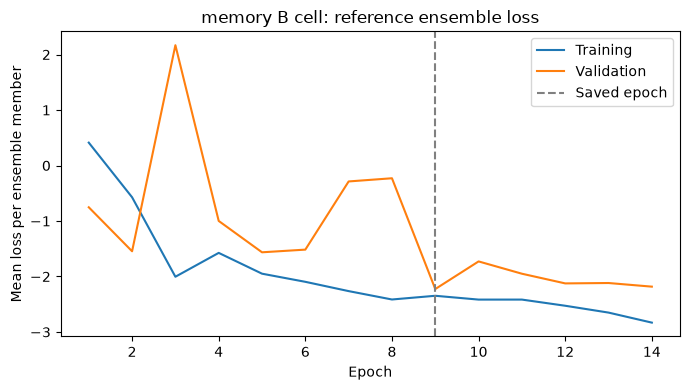

,saved validation epoch
cell_type,memory B cell
epoch,9
train.loss,-2.347406
validation.loss,-2.226157
validation.pc,-0.679136
validation.cosine,0.320864
validation.pnll,0.175373
validation.gnll,-1.885422


In [6]:
import json
import matplotlib.pyplot as plt

history_path = PATHS["teacher"].with_suffix(".history.json")

if history_path.is_file() and PATHS["teacher"].is_file():
    history = pd.json_normalize(json.loads(history_path.read_text()))
    checkpoint = load_native_checkpoint(PATHS["teacher"])
    best_epochs = checkpoint["best_epoch"]
    del checkpoint
    cell_type = CELL_TYPE
    if cell_type not in best_epochs:
        raise ValueError(f"Choose CELL_TYPE from: {', '.join(best_epochs)}")
    cell_history = history.loc[history["cell_type"] == cell_type]
    best_epoch = best_epochs[cell_type]
    best = cell_history.loc[cell_history["epoch"] == best_epoch].iloc[0]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(cell_history["epoch"], cell_history["train.loss"], label="Training")
    ax.plot(cell_history["epoch"], cell_history["validation.loss"], label="Validation")
    ax.axvline(best_epoch, color="grey", linestyle="--", label="Saved epoch")
    ax.set(xlabel="Epoch", ylabel="Mean loss per ensemble member", title=f"{cell_type}: reference ensemble loss")
    ax.legend()
    fig.tight_layout()
    plt.show()
    display(best[["cell_type", "epoch", "train.loss", "validation.loss", "validation.pc",
                  "validation.cosine", "validation.pnll", "validation.gnll"]]
            .rename("saved validation epoch").to_frame())
else:
    print("Loss curves will appear after reference training completes.")


## Evaluate the selected reference model

Once you've chosen hyperparameters using validation genes, set `EVALUATE = True`
to test the saved model on chromosomes **5, 12, and 20**!

Evaluation reports three reference metrics, computed across genes for the
selected cell type:

- Pearson correlation between predicted and observed expression.
- Spearman correlation between epistemic variance and squared prediction error.
- Pearson correlation between aleatoric variance and observed population variance.

These scores compare reference predictions with population expression...
testing personalized accuracy in the held-out OneK1K donors would need their
own personalized embeddings!


In [8]:
EVALUATE = True
EVALUATION_DIR = PATHS["output"] / "reference-evaluation"

evaluation_command = uv(
    "training", "src/training/evaluate.py",
    "--checkpoint", PATHS["teacher"],
    "-o", EVALUATION_DIR,
    "--device", DEVICE,
    *WANDB_ARGS,
)
if EXECUTE and EVALUATE:
    require([PATHS["teacher"]])
run(evaluation_command, execute=EXECUTE and EVALUATE)

summary_path = EVALUATION_DIR / "summary.json"
if summary_path.is_file():
    evaluation = json.loads(summary_path.read_text())
    saved_inputs = evaluation["config"]["inputs"]
    if (saved_inputs[0] != file_fingerprint(PATHS["teacher"])
            or any(saved != file_fingerprint(saved[0]) for saved in saved_inputs)):
        print("Saved evaluation belongs to different or missing inputs. Use a new EVALUATION_DIR.")
    else:
        print(f"Reference test genes: {evaluation['n_test_genes']:,}; cell types: {evaluation['n_cell_types']}")
        display(pd.Series(evaluation["metrics"], name="reference test score").to_frame())
else:
    print("Reference test scores will appear after the optional evaluation.")


Running: uv run --no-sync --extra training python /local1/scratch/pstyll/test/atticus/src/training/evaluate.py --checkpoint /local1/scratch/pstyll/test/atticus/outputs/tutorial/onek1k/memory_B_cell/teacher.pth -o /local1/scratch/pstyll/test/atticus/outputs/tutorial/onek1k/memory_B_cell/reference-evaluation --device auto --wandb-mode disabled


{
  "pearson_across_genes": 0.774059852716577,
  "spearman_epistemic_squared_error": 0.8458032898023372,
  "pearson_aleatoric_population_variance": 0.5148648623940166
}
Reference test genes: 2,339; cell types: 1


,reference test score
pearson_across_genes,0.774060
spearman_epistemic_squared_error,0.845803
pearson_aleatoric_population_variance,0.514865


You should now have `outputs/tutorial/onek1k/memory_B_cell/teacher.pth`, `teacher.history.json`,
and `teacher.splits.json`!

**Next:** [03 · Distill the OneK1K teacher on Geuvadis](03_geuvadis_distillation.ipynb).
